## Fig5A

In [28]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import multiprocessing as mp
from matplotlib import gridspec
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler
from sklearn import metrics
from tqdm import tqdm

In [29]:
names = ['chrom', 'start', 'end', 'name', '?', 'strand', 'thickStart', 'thickEnd',
         'itemRgb', 'coverage', 'score']
chroms = ['L1', 'L2', 'L3', 'L4', 'L5']
pos = [305, 315, 325, 335, 345, 355, 365, 375, 385, 395, 405, 415, 425, 435,
       445, 455, 465, 475, 485, 495, 505, 515, 525, 535, 545, 555, 565, 575,
       585, 595, 605, 615, 625, 635, 645, 655, 665, 675, 685, 695, 705, 715,
       725, 735, 745, 755, 765, 775, 785, 795, 805, 815, 825, 835, 845, 855,
       865, 875, 885, 895, 905, 915, 925, 935, 945, 955, 965, 975, 985, 995]
pos = [p - 1 for p in pos]
seed = 42

In [30]:
data_path = '../data/hu_0612_2/per_read_modified_base_calls.txt'
per_read_hu = pd.read_csv(data_path, sep='\t')
per_read_hu = per_read_hu[per_read_hu.pos.isin(pos)]
per_read_hu['mod_log_prob'] = np.exp(per_read_hu['mod_log_prob'])
dataframes = []
for ch in chroms:
    per_read = per_read_hu[per_read_hu.chrm == ch]
    methyl = {}
    for index, df in per_read.groupby('read_id'):
        methyl[index] = {k: v for k, v in zip(df.pos, df.mod_log_prob)}
    df = pd.DataFrame(methyl).T
    df = df.dropna()
    dataframes.append(df)

In [31]:
n_clusters = [54, 54, 53, 53, 53]
scaler = MinMaxScaler()
tsne = TSNE(random_state=seed, n_jobs=8)

for df, n in zip(dataframes, n_clusters):
    kmeans = KMeans(n_clusters=n, random_state=seed)
    x = scaler.fit_transform(df)
    kmeans.fit(x)
    tsne.fit_transform(x)
    df['label'] = kmeans.labels_

/home/tengjj/anaconda3/envs/experiment/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/home/tengjj/anaconda3/envs/experiment/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/home/tengjj/anaconda3/envs/experiment/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/home/tengjj/anaconda3/envs/experiment/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1412: Fut

In [32]:
for df, chrom in zip(dataframes, chroms):
    df.to_csv(f'../data/hu_0612_2/{chrom}_clustered.csv')

In [33]:
plot_data_L1 = dataframes[0][dataframes[0]['label'] == 0].sample(20)
plot_data_L1

,304,314,324,334,344,354,364,374,384,394,...,914,924,934,944,954,964,974,984,994,label
6ecf690b-1102-47a5-95ef-e6ab3e5bae36,0.738648,0.085005,0.020747,0.527184,0.060870,0.072645,0.271889,0.079975,0.039785,0.062626,...,0.021301,0.023090,0.213121,0.087949,0.966470,0.499034,0.963119,0.688933,0.091143,0
2fe9ceb6-17bc-4b78-836c-51d4fe69fb12,0.933669,0.734926,0.128584,0.023025,0.074225,0.111171,0.229823,0.124760,0.026318,0.080632,...,0.063987,0.044756,0.069260,0.027234,0.807277,0.526103,0.030761,0.437901,0.030211,0
b43344a4-ea36-42a5-bb4b-55da50d65eca,0.044416,0.023917,0.022833,0.055022,0.040246,0.023766,0.077657,0.107452,0.020200,0.040708,...,0.038270,0.059172,0.081499,0.020944,0.971442,0.966993,0.956400,0.865105,0.020218,0
6cbfef9d-d975-452e-85da-0ce27ac5c3ce,0.940794,0.921658,0.030761,0.892273,0.744802,0.068909,0.071108,0.133097,0.091528,0.032262,...,0.055284,0.075842,0.040208,0.023790,0.977410,0.826213,0.079697,0.517559,0.016956,0
7689b1f5-d00b-419a-8098-8bf07e0a5811,0.062481,0.528269,0.027194,0.176512,0.044290,0.040824,0.063160,0.037671,0.028043,0.092179,...,0.117845,0.058766,0.132841,0.923001,0.974950,0.965576,0.986728,0.928546,0.917479,0
e80ca977-5aa9-4b77-829c-6fe6c3404d9d,0.939438,0.885851,0.051833,0.054030,0.098525,0.173298,0.067238,0.118486,0.044842,0.043628,...,0.048802,0.091143,0.222461,0.082491,0.976965,0.152218,0.960243,0.918428,0.033295,0
73d4f177-ddd7-435d-8299-89ffc4cdbf51,0.089883,0.629007,0.024205,0.262920,0.097035,0.033775,0.065726,0.026842,0.022689,0.047500,...,0.063694,0.073421,0.123832,0.103292,0.920749,0.061849,0.445469,0.657587,0.024681,0
57896f48-447b-448b-8fd9-824c9fe24dba,0.415421,0.358856,0.061507,0.038975,0.063451,0.030811,0.021697,0.143091,0.042982,0.069557,...,0.228427,0.063354,0.101490,0.021679,0.962523,0.901246,0.908417,0.746025,0.017164,0
ddfba0fa-324a-48e6-b607-395ef180c544,0.914566,0.796727,0.020107,0.580079,0.081401,0.036174,0.043833,0.052538,0.031863,0.031562,...,0.058664,0.067454,0.783561,0.028140,0.157838,0.044039,0.083412,0.492086,0.033198,0
5c75caa1-26b1-4a17-b820-755f93958869,0.064774,0.960880,0.713466,0.837405,0.164363,0.265534,0.107272,0.182011,0.137032,0.066865,...,0.068394,0.024652,0.094748,0.832814,0.812402,0.909472,0.970400,0.753305,0.091528,0


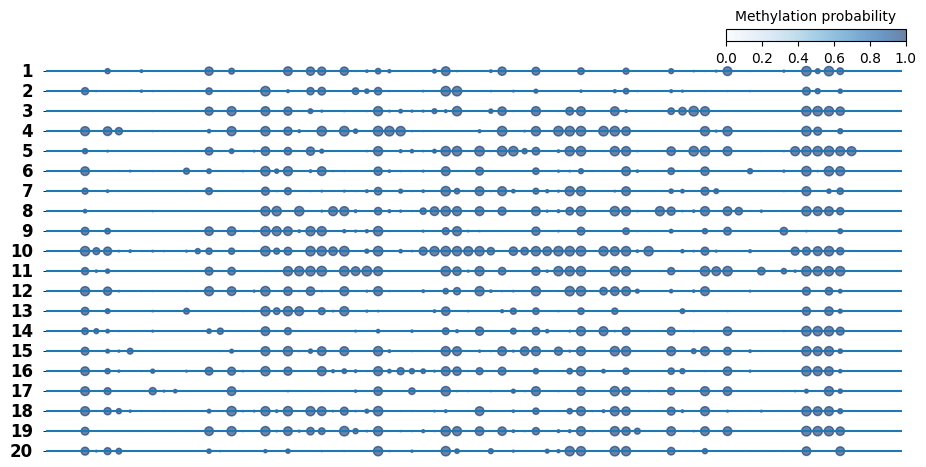

In [34]:
import matplotlib.ticker as ticker
import matplotlib
def plot_per_read_modified(data1, all_sites, save_path=None):
    fig, axes = plt.subplots(20, figsize=(9, 4), sharex='all', sharey='all', constrained_layout=1)
    fig_prop_cycle = plt.rcParams['axes.prop_cycle']()
    X = list(range(len(all_sites)))
    for ax, i, n in zip(axes, data1.index, range(20)):
        # 使用 B_values 作为横轴坐标
        line_data = list(data1.loc[i].values.tolist()[1: ])
        size = 50*(np.array(line_data)**2)
        color = 30*(np.array(line_data)**2)
        scatter = ax.scatter(range(len(all_sites)), [0 for _ in X], s=size, c=color, cmap=matplotlib.colormaps['Blues'], alpha=0.6, vmin=0, vmax=1)
        for x in 'left top right bottom'.split(): 
            ax.spines[x].set_visible(False)
    
        ax.set_yticks(range(0, 1))
        ax.set_ylim((-1, 1))
        ax.set_yticks(range(1), minor=True)
    
        ax.axhline(0)
    
        ax.set_yticks([])
        ax.set_yticklabels([])
        ax.set_xticks([])
        ax.set_xticklabels([])
        
        ax.set_ylabel(n+1, rotation=0, ha='right', va='center', fontsize=12, fontweight='bold')
    
    
    # 调整colorbar的位置和长度
    cbar_ax = fig.add_axes([0.8, 1.05, 0.2, 0.03])
    cbar = plt.colorbar(scatter, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Methylation probability',  labelpad=-40)
    cbar.locator = ticker.MaxNLocator(nbins=5)
    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
    else:
        plt.show()
plot_per_read_modified(plot_data_L1, pos, save_path='./fig5_L1.svg')

## Fig5B

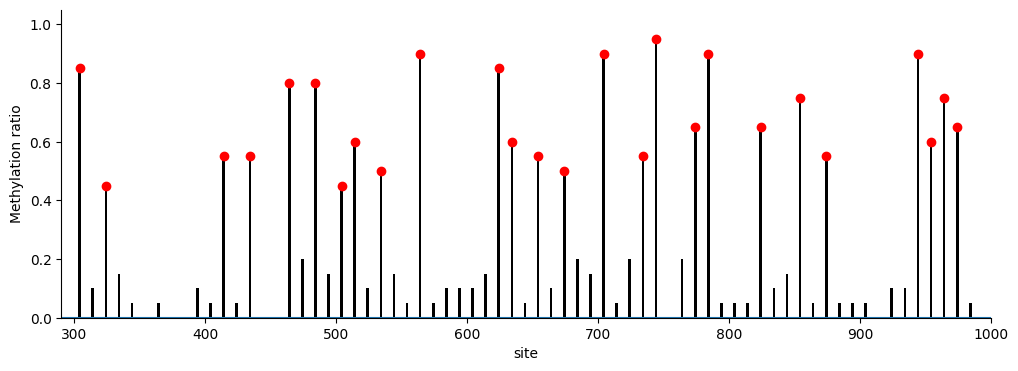

In [35]:
def plot_per_site_methylation(in_df, me_sites, label, length,threshold=0.5):
    plot_data = in_df[(in_df['label'] == label)]
    plot_data_col = plot_data.columns[1:71]
    plot_data[plot_data_col] = (plot_data[plot_data_col] > threshold).astype(int)
    sorted_data = plot_data.iloc[:,1:71].mean()
    x = np.arange(length)
    y = np.zeros(length)
    for p, row in zip(pos, sorted_data):
        y[int(p)] += row
    fig, ax = plt.subplots(figsize=(12,4))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.bar(x, y, width=2, color='black')
    plt.hlines(y=0, xmin=0, xmax=length)
    plt.scatter(x=me_sites, y=[y[i] for i in me_sites], c='red')
    plt.xlabel('site')
    plt.ylabel('Methylation ratio')
    plt.grid(False)
    plt.xlim(290, 1000)
    plt.ylim(0, 1.05)
    plt.savefig('fig5B.svg', bbox_inches='tight')
plot_per_site_methylation(plot_data_L1,
                        [304,324,414,434,464,484,504,514,534,564,624,634,654,674,704,734,744,774,784,824,854,874,944,954,964,974],
                        label=0,
                        length=1300,
                        threshold=0.5)

## Fig5C

In [47]:
df_L1 = pd.read_csv('../data/hu_0612_2/L1_clustered.csv')
df_L1

,Unnamed: 0,304,314,324,334,344,354,364,374,384,...,914,924,934,944,954,964,974,984,994,label
0,00000cc7-96e6-4fe4-8ff9-09e40072492e,0.110219,0.077487,0.950787,0.176152,0.191969,0.959375,0.094332,0.854727,0.021715,...,0.020801,0.900094,0.284386,0.060027,0.039439,0.917955,0.078175,0.120225,0.957803,31
1,00044225-1d4a-4831-9f11-1dfe8e6ff6a8,0.154375,0.937696,0.168766,0.607319,0.828120,0.717293,0.072715,0.122233,0.912565,...,0.811385,0.056071,0.865105,0.131064,0.122233,0.723637,0.307723,0.243704,0.035740,20
2,00061b02-3f6a-4b91-8a0b-5835a957cb22,0.958485,0.958709,0.938399,0.028627,0.072854,0.881822,0.021016,0.145381,0.879061,...,0.022468,0.913571,0.916036,0.807277,0.024623,0.067184,0.205829,0.269227,0.874083,18
3,00072dd2-702f-4132-9ff1-1d698743915e,0.097774,0.026428,0.029663,0.426469,0.031512,0.019102,0.047083,0.075921,0.080918,...,0.171539,0.039439,0.122007,0.961090,0.975442,0.935533,0.981848,0.926886,0.847997,32
4,00073c79-e303-41ad-9b16-2e0cd69da206,0.183132,0.020144,0.083934,0.143944,0.089147,0.074525,0.122686,0.807277,0.080727,...,0.063694,0.889747,0.018820,0.021248,0.020837,0.033101,0.128829,0.609846,0.024098,30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26382,fff4eef7-c90b-468a-b962-e297a20c5e37,0.034012,0.091143,0.261880,0.067617,0.271355,0.077402,0.703191,0.060176,0.023383,...,0.063548,0.074449,0.114929,0.975198,0.985583,0.820393,0.099442,0.926465,0.037952,36
26383,fff7e6ec-a4b1-420b-b1d5-42d969a820a7,0.058919,0.842776,0.019595,0.581293,0.057064,0.067024,0.137032,0.274570,0.972994,...,0.975564,0.960880,0.076162,0.094332,0.980529,0.985957,0.826213,0.432135,0.802051,52
26384,fffa8739-535b-4b6f-9e9c-b6d7eb942512,0.040477,0.648454,0.118058,0.105854,0.048185,0.052285,0.063014,0.694132,0.051833,...,0.063063,0.054082,0.896556,0.218859,0.257752,0.931355,0.947680,0.827168,0.732432,16
26385,fffc4590-c7f6-4b54-a9c4-b523e1cb124e,0.040631,0.031312,0.058868,0.106381,0.071433,0.055599,0.515453,0.302482,0.106029,...,0.712187,0.088067,0.896556,0.034846,0.958485,0.075842,0.407747,0.261880,0.025519,50


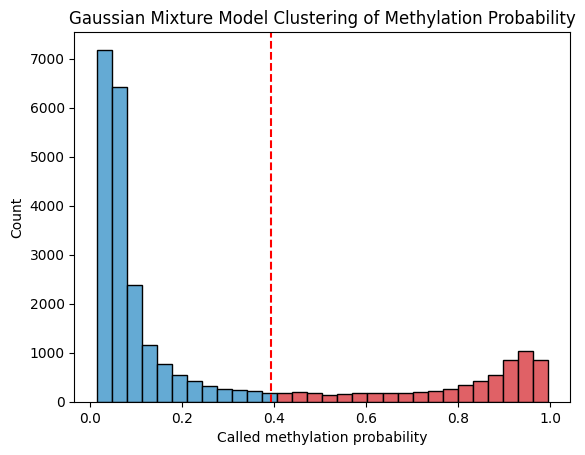

In [51]:
from sklearn.mixture import GaussianMixture
cluster_data = df_L1['304'].to_numpy()
gmm = GaussianMixture(n_components=2, random_state=0, covariance_type='spherical').fit(cluster_data.reshape(-1,1))
th = gmm.means_[0][0] * gmm.weights_[1] + gmm.means_[1][0] * gmm.weights_[0]
ax = sns.histplot(cluster_data, bins=30)
for patch in ax.patches:
    # 获取柱子的中心位置
    x_center = patch.get_x() + patch.get_width() / 2
    
    # 大于阈值 → 红色；小于阈值 → 绿色
    if x_center > th:
        patch.set_facecolor('#E06166')    # 高于阈值：红色
    else:
        patch.set_facecolor('#64AAD4')  # 低于阈值：绿色
plt.axvline(th, color='red', linestyle='--')
plt.xlabel('Called methylation probability')
plt.ylabel('Count')
plt.title('Gaussian Mixture Model Clustering of Methylation Probability')
plt.savefig('fig5C.svg', bbox_inches='tight')

## Fig5D

In [38]:
import pysam

reference = pysam.Fastafile('../data/hu-reference.fasta')
error_rate_6_3 = np.load('../data/error_rate_0603.npy',allow_pickle=True).item()
error_rate_0612_1 = np.load('../data/error_rate_0612_1.npy',allow_pickle=True).item()
error_rate_0612_2 = np.load('../data/error_rate_0612_2.npy',allow_pickle=True).item()

['L3_664', 'L1_554', 'L1_644', 'L4_424', 'L3_424', 'L3_314', 'L3_654', 'L1_524', 'L2_464', 'L2_974', 'L3_564', 'L1_984', 'L1_564', 'L5_964', 'L3_364', 'L5_744']


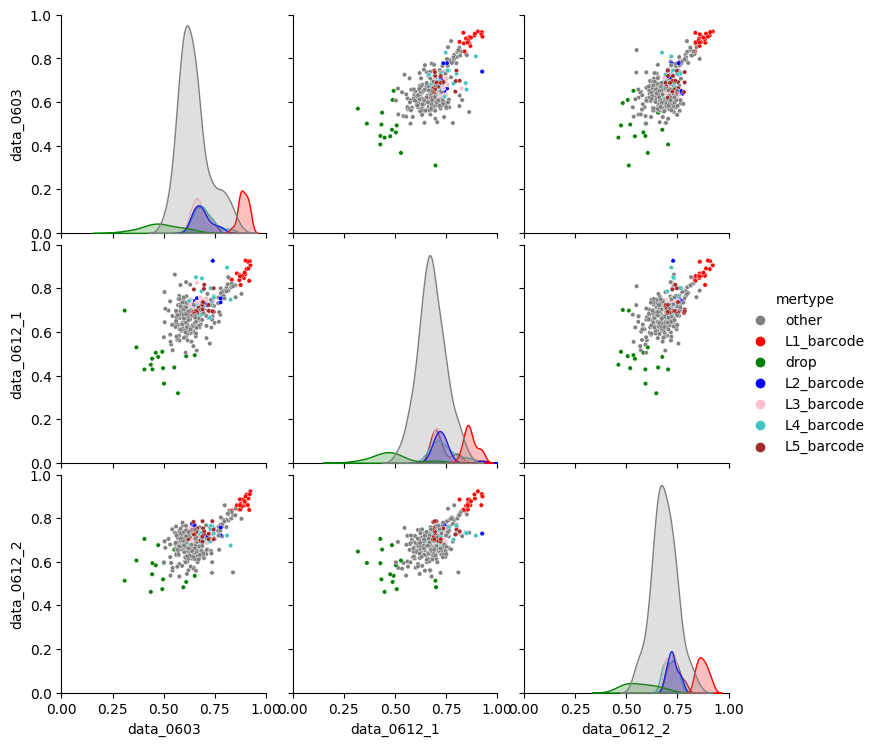

In [46]:
barcode_list = ['L1_764', 'L1_924', 'L1_754', 'L1_414', 'L1_684', 'L1_394', 'L1_794', 'L1_434', 'L1_874', 'L1_994', 'L1_854', 'L1_534', 'L1_654', 'L1_774', 'L1_934', 'L1_384', 'L1_964', 'L1_354', 'L1_954', 'L1_894','L2_884', 'L2_934', 'L2_524', 'L2_424', 'L2_764', 'L2_574', 'L2_374', 'L2_304', 'L2_594', 'L2_364', 'L2_984', 'L2_704', 'L2_954', 'L2_894', 'L2_614', 'L2_874', 'L2_354', 'L2_664', 'L2_434', 'L2_394','L3_974', 'L3_464', 'L3_544', 'L3_794', 'L3_964', 'L3_504', 'L3_804', 'L3_844', 'L3_984', 'L3_414', 'L3_634', 'L3_454', 'L3_604', 'L3_644', 'L3_834', 'L3_954', 'L3_494', 'L3_764', 'L3_814', 'L3_354','L4_684', 'L4_434', 'L4_514', 'L4_714', 'L4_964', 'L4_454', 'L4_394', 'L4_784', 'L4_764', 'L4_584', 'L4_914', 'L4_594', 'L4_644', 'L4_994', 'L4_844', 'L4_944', 'L4_624', 'L4_974', 'L4_534', 'L4_954', 'L4_904', 'L4_574','L5_734', 'L5_584', 'L5_344', 'L5_764', 'L5_894', 'L5_904', 'L5_844', 'L5_534', 'L5_754', 'L5_484', 'L5_364', 'L5_914', 'L5_374', 'L5_354', 'L5_334', 'L5_784', 'L5_494', 'L5_824', 'L5_974', 'L5_984']
worst_list = set()
for chr in reference.references:
    for i in range(304,999,10):
        if error_rate_6_3[chr][i]>=0.5:
            worst_list.add(chr+'_'+str(i))
        if error_rate_0612_1[chr][i]>=0.5:
            worst_list.add(chr+'_'+str(i))
        if error_rate_0612_2[chr][i]>=0.5:
            worst_list.add(chr+'_'+str(i))
print(list(worst_list))
data_0603 = []
data_0612_1 = []
data_0612_2 = []
is_repeat = []
for chr in reference.references:
    for i in range(304,999,10):
        data_0603.append(1-error_rate_6_3[chr][i])
        data_0612_1.append(1-error_rate_0612_1[chr][i])
        data_0612_2.append(1-error_rate_0612_2[chr][i])
        if (chr+'_'+str(i)) in barcode_list:
            is_repeat.append(chr+'_barcode')
        elif (chr+'_'+str(i)) in worst_list:
            is_repeat.append('drop')
        else:
            is_repeat.append('other')
plot_data2 = pd.DataFrame({
    'data_0603':data_0603,
    'data_0612_1':data_0612_1,
    'data_0612_2':data_0612_2,
    'mertype':is_repeat
})
import seaborn as sns
ax = sns.pairplot(plot_data2, diag_kind='kde',hue='mertype',plot_kws={'s':10},palette={'other':'grey','L1_barcode':'red','L2_barcode':'blue','L3_barcode':'pink','L4_barcode':'#43C6C3','L5_barcode':'brown','drop':'green'})
ax.set(xlim=(0,1))
ax.set(ylim=(0,1))
ax.savefig('mertype_correlation4.png')

/home/tengjj/.local/lib/python3.8/site-packages/seaborn/axisgrid.py:1877: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(x=self.x, ax=self.ax_marg_x, **kwargs)
/home/tengjj/.local/lib/python3.8/site-packages/seaborn/axisgrid.py:1883: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(y=self.y, ax=self.ax_marg_y, **kwargs)


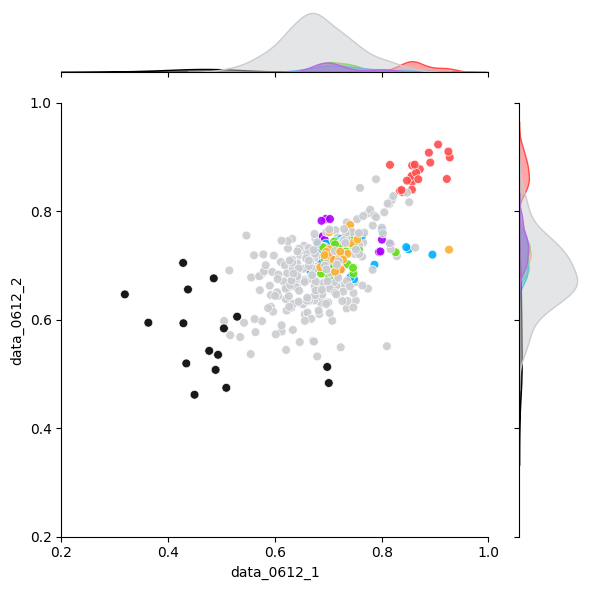

In [ ]:
colors = {'other':'#caccd1','L1_barcode':'#ff4c4c','L2_barcode':'#fbb034','L3_barcode':'#64dd17','L4_barcode':'#00b0ff','L5_barcode':'#aa00ff','drop':'#000000'}
# ["#000000", "#ff4c4c", "#fbb034", "#64dd17", "#00b0ff", "#aa00ff", "#caccd1"][::-1]
g = sns.JointGrid(x='data_0612_1', y='data_0612_2', data=plot_data2[::-1], space=0.5, xlim=(0.2, 1), ylim=(0.2, 1), hue='mertype',
                  palette=colors)
g.plot_joint(sns.scatterplot, s=40, alpha=0.9)
g.plot_marginals(sns.kdeplot, shade=True, alpha=0.5)
g.ax_joint.set_xticks([0.2, 0.4, 0.6, 0.8, 1])
g.ax_joint.set_yticks([0.2, 0.4, 0.6, 0.8, 1])
g.ax_joint.legend().remove()
plt.savefig('fig5d.svg', dpi=300, format='svg')